# Final Project — From Hidden Structure to Prediction
## Dataset: Digits (Handwritten Digit Recognition)

**Authors:** Aitor Marcalain and Eneko Iza  
**Date:** May 2026

---

### Notebook Structure
1. Problem Formulation
2. Data Understanding & Preprocessing
3. Unsupervised Learning (PCA, t-SNE, Clustering)
4. Supervised Learning (Classification)
5. Evaluation
6. Connection Between the Two Parts
7. Reflection

## 0. Imports & Setup

We load all libraries needed throughout the project here.  
Centralising them in one place improves reproducibility and avoids scattered imports.

In [1]:
# --- Standard libraries ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- Dataset ---
from sklearn.datasets import load_digits

# --- Preprocessing ---
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV

# --- Unsupervised ---
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score

# --- Supervised ---
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# --- Evaluation ---
from sklearn.metrics import (
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score
)

# Silence convergence warnings from the saga solver during the grid search
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Reproducibility
SEED = 42
np.random.seed(SEED)

# Plot style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

---
## 1. Problem Formulation

### What is the dataset?
The **Digits** dataset from scikit-learn contains **1,797 images** of handwritten digits (0-9),  
each represented as an 8x8 pixel grid -> **64 numerical features** (values from 0 to 16).

### Research question
We want to investigate two things:
- **Unsupervised:** Do latent structures exist in pixel space that allow us to separate  
  digits visually without using any labels?
- **Supervised:** Can we predict the digit (0-9) from pixel values?  
  Which methods work best, and why?

### Why is this interesting?
Digit recognition is the *Hello World* of machine learning, yet it remains a relevant  
benchmark for comparing methods. The visual nature of the dataset also makes results  
easy to interpret: we can literally *see* what the model learns.

### Supervised target
**Multiclass classification:** predict the digit label (0-9) from the 64 pixel values.

### Unsupervised goal
Discover whether dimensionality reduction and clustering methods can recover the 10 digit  
groups without ever accessing the labels.

---
## 2. Data Understanding & Preprocessing

### Thinking process
Before applying any algorithm we need to understand the data:
- How many samples and features do we have?
- Are there any missing values?
- Are the classes balanced?
- What do the images actually look like?
- Do we need to scale the data?  
  **Yes** — many algorithms (SVM, KNN, PCA) are sensitive to feature scale.

The **train/test split** is performed once here and reused throughout the project  
to avoid data leakage and ensure a fair model comparison.

In [2]:
# Load the dataset
digits = load_digits()
X = digits.data          # (1797, 64)
y = digits.target        # (1797,)  values 0-9
images = digits.images   # (1797, 8, 8) -- useful for visualisation

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Classes: {np.unique(y)}")

X shape: (1797, 64)
y shape: (1797,)
Classes: [0 1 2 3 4 5 6 7 8 9]


In [3]:
# ---- 2.1 Missing values & basic statistics ----
# Check for NaN values
print("Missing values in X:", np.isnan(X).sum())

# Describe statistics (min, max, mean, std)
print("\nBasic statistics for X:")
print(f"  Min: {X.min()}")
print(f"  Max: {X.max()}")
print(f"  Mean: {X.mean():.2f}")
print(f"  Std: {X.std():.2f}")

Missing values in X: 0

Basic statistics for X:
  Min: 0.0
  Max: 16.0
  Mean: 4.88
  Std: 6.02


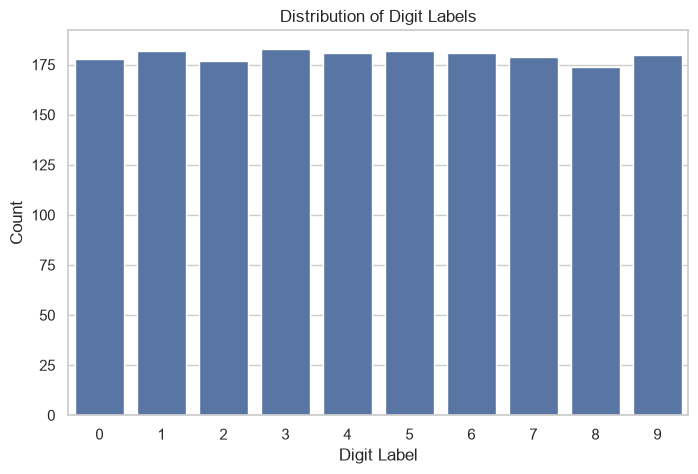

In [4]:
# ---- 2.2 Class balance ----
# Bar chart showing the distribution of each digit label
plt.figure(figsize=(8, 5))
sns.countplot(x=y)
plt.title('Distribution of Digit Labels')
plt.xlabel('Digit Label')
plt.ylabel('Count')
plt.show()

# Reflection: is the dataset balanced? Does this affect our choice of metrics?
# The dataset appears to be well-balanced, with each digit class having approximately 170-180 samples.
# This means we don't have to worry excessively about class imbalance and can use metrics like accuracy directly,
# although precision, recall, and F1-score will still be important for a full evaluation.

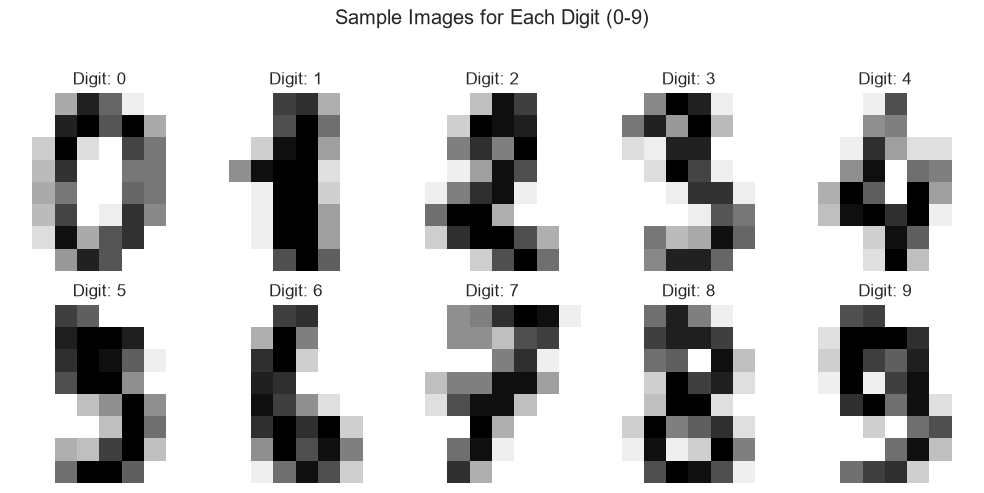

In [5]:
# ---- 2.3 Sample visualisation ----
# Display a grid with one example image per digit (0-9)
# This helps us understand the difficulty of the problem:
# some digits look very similar to each other (4 and 9, 3 and 8).

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(10, 5))
axes = axes.flatten()

for i in range(10):
    # Find the index of the first occurrence of digit i
    idx = np.where(y == i)[0][0]
    axes[i].imshow(images[idx], cmap=plt.cm.gray_r, interpolation='nearest')
    axes[i].set_title(f'Digit: {i}')
    axes[i].axis('off')

plt.suptitle('Sample Images for Each Digit (0-9)', y=1.02)
plt.tight_layout()
plt.show()

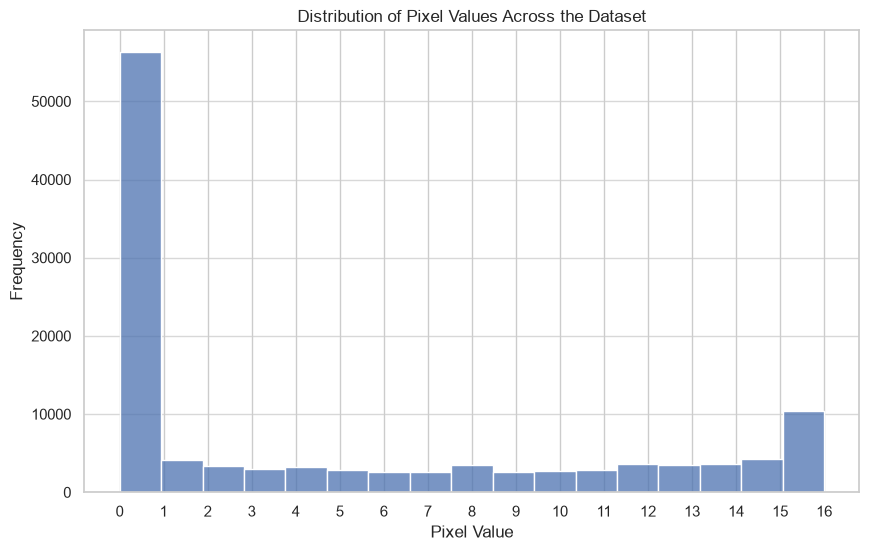

In [6]:
# ---- 2.4 Pixel value distribution ----
# Histogram of pixel values across the entire dataset
# Many pixels are 0 (background) -> skewed distribution.

plt.figure(figsize=(10, 6))
sns.histplot(X.flatten(), bins=17, kde=False) # Bins from 0 to 16
plt.title('Distribution of Pixel Values Across the Dataset')
plt.xlabel('Pixel Value')
plt.ylabel('Frequency')
plt.xticks(range(0, 17)) # Ensure all integer pixel values are shown on x-axis
plt.grid(axis='y', alpha=0.75)
plt.show()

# Reflection: As expected, the distribution is heavily skewed towards 0, as many pixels in handwritten digits
# are part of the background and thus have a value of 0. There's also a peak at higher values (around 16),
# indicating the intensity of the digit strokes themselves.

In [7]:
# ---- 2.5 Scaling & train/test split ----
# We use StandardScaler: each feature will have mean=0 and std=1.
# IMPORTANT: the scaler is fitted on train data ONLY, then applied to test.
# Fitting on the full dataset would leak information into the test set.

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

# We also scale the full dataset for the unsupervised part
X_scaled = scaler.fit_transform(X)

print(f"Train: {X_train_scaled.shape} | Test: {X_test_scaled.shape}")
print(f"y_train shape: {y_train.shape} | y_test shape: {y_test.shape}")

Train: (1437, 64) | Test: (360, 64)
y_train shape: (1437,) | y_test shape: (360,)


---
## 3. Unsupervised Learning

### Thinking process
We have 64 dimensions -- too many to visualise directly. The plan:
1. **PCA** -- linear reduction: how much variance do a few components capture?  
   Do the digit classes separate in the space of the first principal components?
2. **t-SNE** -- non-linear reduction: better for visualising clusters in 2D.  
   Slower and axes have no direct interpretation, but it captures local structure well.
3. **Clustering** -- without labels, can we recover 10 groups?  
   We use **k-means** and **agglomerative clustering**.  
   To evaluate, we compare clusters to the true labels using silhouette score.

> **Note:** All unsupervised analysis uses `X_scaled` (the full scaled dataset),  
> since we do not rely on labels here.

### 3.1 PCA -- Principal Component Analysis

PCA finds the directions of maximum variance in the data.
- First we analyse how many components are needed (explained variance curve).
- Then we project to 2D for visual inspection.

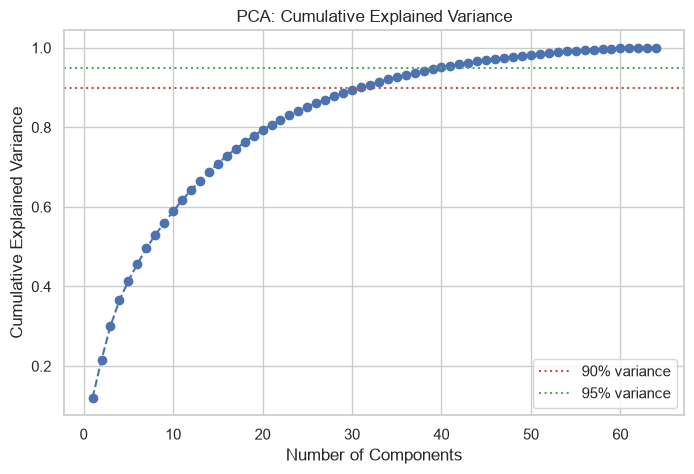

Components for 90% variance: 31
Components for 95% variance: 40


In [8]:
# ---- 3.1a Cumulative explained variance ----
# Fit PCA with all components
pca_all = PCA(random_state=SEED)
pca_all.fit(X_scaled)
cumulative_variance = np.cumsum(pca_all.explained_variance_ratio_)

# Plot cumulative explained variance vs number of components
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.axhline(y=0.90, color='r', linestyle=':', label='90% variance')
plt.axhline(y=0.95, color='g', linestyle=':', label='95% variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('PCA: Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

# Question: how many components capture 90% / 95% of the variance?
n90 = np.argmax(cumulative_variance >= 0.90) + 1
n95 = np.argmax(cumulative_variance >= 0.95) + 1
print(f"Components for 90% variance: {n90}")
print(f"Components for 95% variance: {n95}")

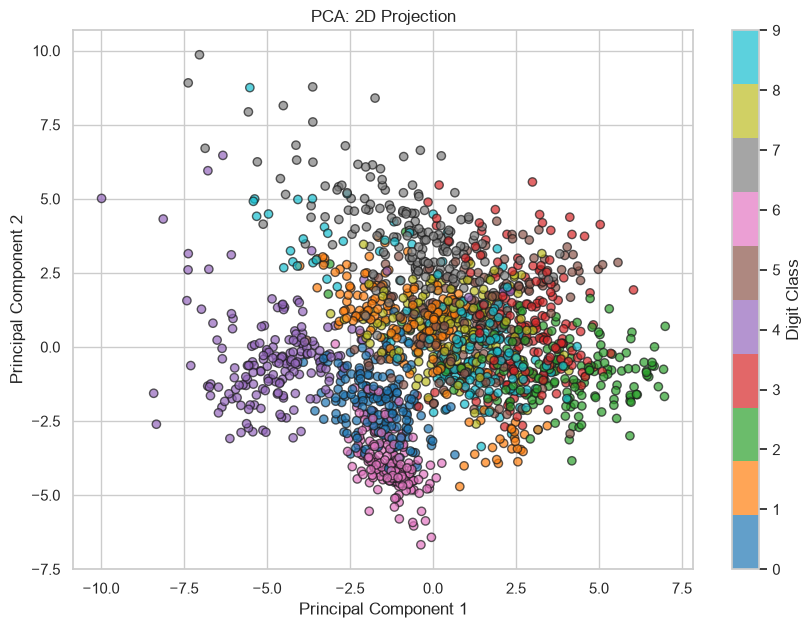

In [9]:
# ---- 3.1b 2D projection ----
# Fit PCA with n_components=2
pca_2d = PCA(n_components=2, random_state=SEED)
X_pca_2d = pca_2d.fit_transform(X_scaled)

# Scatter plot coloured by true digit label
plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='tab10', alpha=0.7, edgecolor='k')
plt.colorbar(scatter, label='Digit Class')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA: 2D Projection')
plt.show()

### 3.2 t-SNE -- Non-linear Visualisation

t-SNE minimises the KL divergence between high- and low-dimensional distance distributions.  
It is excellent at revealing clusters, but axes are not interpretable and results depend  
on the `perplexity` hyperparameter. We will try several values.

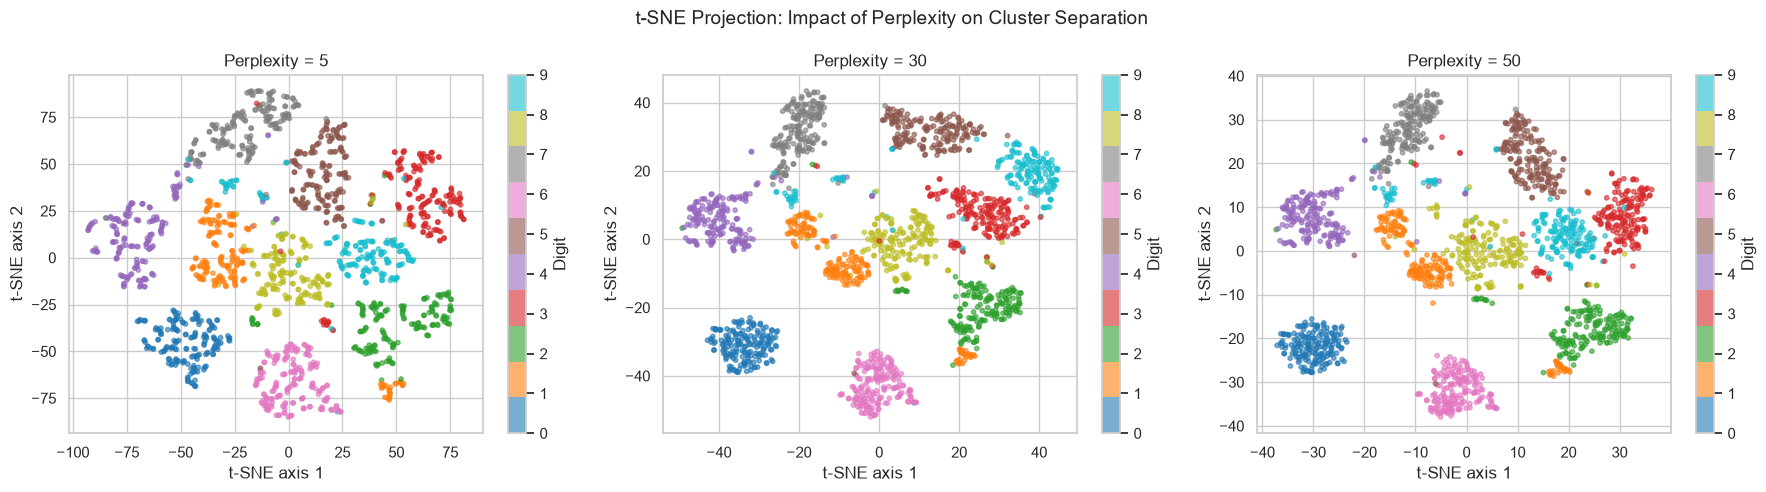

In [10]:
# ---- 3.2 t-SNE ----
# Apply t-SNE with perplexity=[5, 30, 50] and compare results
# Scatter plot in 2D coloured by true digit label

perplexities = [5, 30, 50]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, p in enumerate(perplexities):
    # Initialize t-SNE with current perplexity
    # We use random_state for reproducibility and init='pca' for better stability
    tsne = TSNE(n_components=2, perplexity=p, random_state=SEED, init='pca', learning_rate='auto')
    X_tsne_iter = tsne.fit_transform(X_scaled)

    scatter = axes[i].scatter(X_tsne_iter[:, 0], X_tsne_iter[:, 1], c=y, cmap='tab10', alpha=0.6, s=10)
    axes[i].set_title(f"Perplexity = {p}")
    axes[i].set_xlabel("t-SNE axis 1")
    axes[i].set_ylabel("t-SNE axis 2")

    # Adding a colorbar to each subplot to identify digits
    plt.colorbar(scatter, ax=axes[i], label='Digit')

plt.suptitle("t-SNE Projection: Impact of Perplexity on Cluster Separation", fontsize=14)
plt.tight_layout()
plt.show()

# Reflection: is the separation cleaner than with PCA?
# Yes, t-SNE provides much better separation than PCA. While PCA shows
# significant overlap between classes (especially in the center), t-SNE
# manages to group almost all digits into distinct, well-defined clusters.

# Limitation: t-SNE is not reproducible without fixing random_state and is computationally expensive O(n^2).

### 3.3 Clustering

We apply clustering on the original scaled space (64D) and on the PCA-reduced space,  
then compare both approaches.

**Evaluation metric:**
- **Silhouette Score:** how well-separated the clusters are internally (no labels needed).



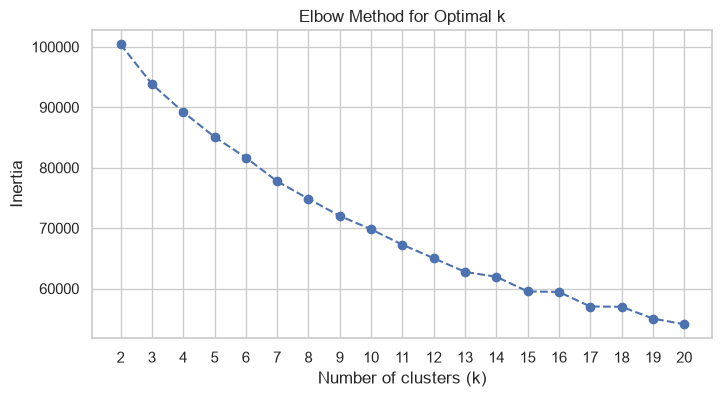

K-Means (k=10) Performance:
  Silhouette Score: 0.1394


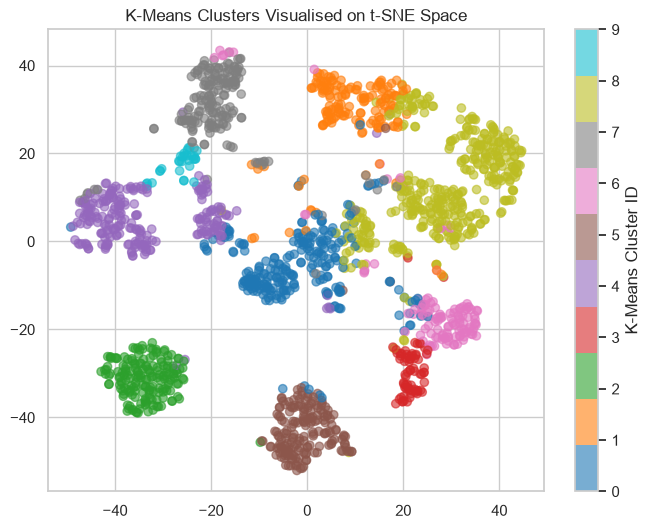

In [11]:
# ---- 3.3a K-Means ----
# We know a priori there are 10 digits -> k=10 is the natural choice.
# We also use the elbow method (inertia) to justify this.

# Elbow curve (inertia vs k) for k in range(2, 20)
inertia = []
k_range = range(2, 21)
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    km.fit(X_scaled)
    inertia.append(km.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia, marker='o', linestyle='--')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Fit KMeans with k=10
kmeans = KMeans(n_clusters=10, n_init=10, random_state=SEED)
km_labels = kmeans.fit_predict(X_scaled)

# Compute  Silhouette Score
sil_km = silhouette_score(X_scaled, km_labels)

print(f"K-Means (k=10) Performance:")
print(f"  Silhouette Score: {sil_km:.4f}")

# Visualise clusters in t-SNE space
tsne_ref = TSNE(n_components=2, perplexity=30, random_state=SEED, init='pca', learning_rate='auto')
X_tsne = tsne_ref.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=km_labels, cmap='tab10', alpha=0.6)
plt.colorbar(label='K-Means Cluster ID')
plt.title("K-Means Clusters Visualised on t-SNE Space")
plt.show()

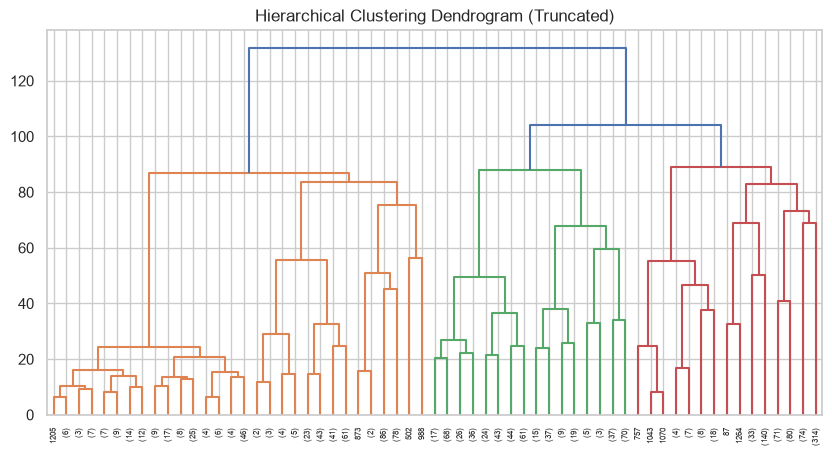

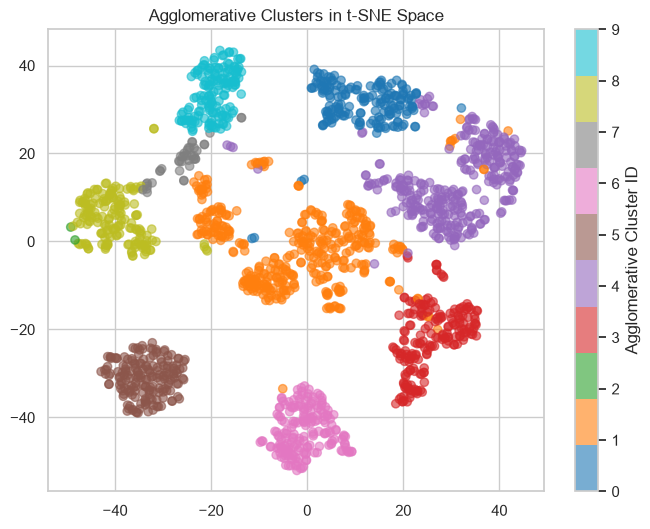

In [12]:
# ---- 3.3b Agglomerative (Hierarchical) Clustering ----
# Unlike k-means, this does not assume spherical clusters.
# We use linkage='ward' (minimises intra-cluster variance).

from scipy.cluster.hierarchy import dendrogram, linkage

# Fit AgglomerativeClustering with n_clusters=10
agg = AgglomerativeClustering(n_clusters=10, linkage='ward')
agg_labels = agg.fit_predict(X_scaled)

# Compute Silhouette Score
sil_agg = silhouette_score(X_scaled, agg_labels)

# Dendrogram (optional, using scipy.cluster.hierarchy)
plt.figure(figsize=(10, 5))
dendrogram(linkage(X_scaled, method='ward'), truncate_mode='level', p=5)
plt.title("Hierarchical Clustering Dendrogram (Truncated)")
plt.show()

# Compare visually with k-means in t-SNE space
plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=agg_labels, cmap='tab10', alpha=0.6)
plt.colorbar(label='Agglomerative Cluster ID')
plt.title("Agglomerative Clusters in t-SNE Space")
plt.show()

In [13]:
# ---- 3.3c Clustering comparison table ----
# Table with ARI and Silhouette for:
#   - K-Means on original space
#   - K-Means on PCA space
#   - Agglomerative on original space
#   - Agglomerative on PCA space

# We compare original space vs PCA space (2D)
pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_scaled)

results = []

# K-Means Original
results.append({'Method': 'K-Means', 'Space': 'Original',
                 'Silhouette': sil_km})

# K-Means PCA
km_pca_labels = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit_predict(pca_2d)
results.append({'Method': 'K-Means', 'Space': 'PCA (2D)',
                'Silhouette': silhouette_score(pca_2d, km_pca_labels)})

# Agglomerative Original
results.append({'Method': 'Agglomerative', 'Space': 'Original',
                 'Silhouette': sil_agg})

# Agglomerative PCA
agg_pca_labels = AgglomerativeClustering(n_clusters=10).fit_predict(pca_2d)
results.append({'Method': 'Agglomerative', 'Space': 'PCA (2D)',
                'Silhouette': silhouette_score(pca_2d, agg_pca_labels)})

comparison_df = pd.DataFrame(results)
print(comparison_df)

          Method     Space  Silhouette
0        K-Means  Original    0.139377
1        K-Means  PCA (2D)    0.377803
2  Agglomerative  Original    0.125325
3  Agglomerative  PCA (2D)    0.311290


---
## 4. Supervised Learning -- Classification

### Thinking process
The goal is to predict the digit label (0-9) from pixel values.  
This is a **multiclass classification** problem.

We compare models of increasing complexity:
- **Logistic Regression** -- linear model, fast, interpretable (baseline).
- **K-Nearest Neighbors (KNN)** -- non-parametric, flexible, distance-sensitive.
- **Support Vector Machine (SVM, RBF kernel)** -- maximum-margin classifier,  
  generally very competitive on this type of data.

We use **cross-validation** to select hyperparameters and avoid overfitting.  
The final evaluation is performed only once on the **held-out test set**.

In [14]:
# ---- 4.1 Logistic Regression (Baseline) ----
# Linear model: finds separating hyperplanes in the 64-dimensional feature space.
# We set max_iter high because convergence can be slow with many features.

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

# Create a pipeline that first scales the data, then applies Logistic Regression
pipeline_log_reg = Pipeline([
    ('scaler', StandardScaler()),
    ('log_reg', LogisticRegression(max_iter=1000, random_state=SEED))
])

# Define the parameter grid for Logistic Regression
# 'C' is the inverse of regularization strength; smaller values specify stronger regularization.
# 'solver' specifies the algorithm to use in the optimization problem.
param_grid_log_reg = {
    'log_reg__C': [0.01, 0.1, 1, 10, 100],
    'log_reg__solver': ['lbfgs', 'saga']
}

# Perform GridSearchCV to find the best parameters
grid_search_log_reg = GridSearchCV(pipeline_log_reg, param_grid_log_reg, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_log_reg.fit(X_train, y_train) # Fit on original X_train, pipeline handles scaling

# Get best parameters and its score
best_log_reg_params = grid_search_log_reg.best_params_
best_log_reg_score = grid_search_log_reg.best_score_
print(f"Best parameters for Logistic Regression: {best_log_reg_params}")
print(f"Best cross-validation accuracy for Logistic Regression: {best_log_reg_score:.4f}")

Best parameters for Logistic Regression: {'log_reg__C': 1, 'log_reg__solver': 'saga'}
Best cross-validation accuracy for Logistic Regression: 0.9708


Best k for KNN: 5
Best cross-validation accuracy for KNN: 0.9749


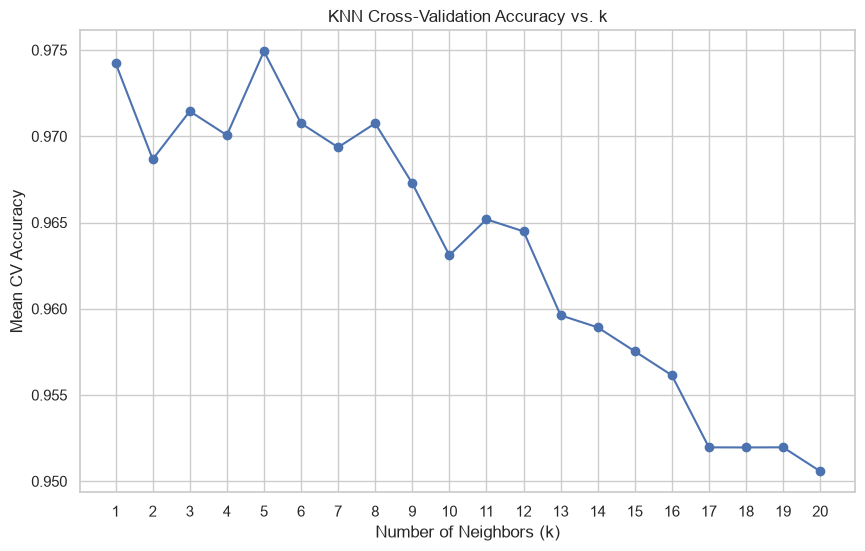

In [15]:
# ---- 4.2 K-Nearest Neighbors ----
# KNN classifies each sample based on the k closest neighbours in feature space.
# Key hyperparameter: k (number of neighbours)

# Create a pipeline that first scales the data, then applies KNeighborsClassifier
pipeline_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

# Define the parameter grid for k (note the 'knn__' prefix for pipeline parameters)
param_grid = {'knn__n_neighbors': range(1, 21)}

# Perform GridSearchCV to find the best k
# We fit on the ORIGINAL X_train because the pipeline handles scaling internally
grid_search = GridSearchCV(pipeline_knn, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train, y_train)

# Get best k and its score
best_k = grid_search.best_params_['knn__n_neighbors']
best_knn_score = grid_search.best_score_
print(f"Best k for KNN: {best_k}")
print(f"Best cross-validation accuracy for KNN: {best_knn_score:.4f}")

# Plot CV accuracy vs k
results = grid_search.cv_results_['mean_test_score']
plt.figure(figsize=(10, 6))
plt.plot(range(1, 21), results, marker='o', linestyle='-')
plt.title('KNN Cross-Validation Accuracy vs. k')
plt.xlabel('Number of Neighbors (k)')
plt.ylabel('Mean CV Accuracy')
plt.xticks(range(1, 21))
plt.grid(True)
plt.show()

# Store the best KNN model
best_knn_model = grid_search.best_estimator_

# Reflection: small k -> overfitting; large k -> underfitting.
# With a small k (e.g., k=1), the model is highly sensitive to noise in the training data,
# leading to a more complex decision boundary and potential overfitting. As k increases,
# the model considers more neighbors, leading to a smoother decision boundary, which can
# reduce the impact of noise but might lead to underfitting if k is too large (i.e., decision
# boundary becomes too generalized). The plot helps identify the optimal balance.

In [16]:
# ---- 4.3 Support Vector Machine (RBF kernel) ----
# SVM with RBF kernel maps data to a high-dimensional space and finds
# the maximum-margin separating hyperplane.
# Key hyperparameters: C (regularisation strength) and gamma (kernel width)

# Create a pipeline that first scales the data, then applies SVC
pipeline_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(random_state=SEED))
])

# Define the parameter grid for C and gamma (note the 'svc__' prefix for pipeline parameters)
param_grid_svm = {
    'svc__C': [0.1, 1, 10, 100],
    'svc__gamma': [0.001, 0.01, 0.1, 1]
}

# Perform GridSearchCV to find the best C and gamma
grid_search_svm = GridSearchCV(pipeline_svm, param_grid_svm, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_svm.fit(X_train, y_train) # Fit on original X_train, pipeline handles scaling

# Get best parameters and its score
best_svm_params = grid_search_svm.best_params_
best_svm_score = grid_search_svm.best_score_
print(f"Best parameters for SVM: {best_svm_params}")
print(f"Best cross-validation accuracy for SVM: {best_svm_score:.4f}")

# Store the best SVM model
best_svm_model = grid_search_svm.best_estimator_

# Reflection: typically the most accurate model for this dataset.
# SVMs with RBF kernels are powerful for non-linear decision boundaries. The GridSearchCV
# helps us find the optimal balance between model complexity (C) and the influence of
# individual training samples (gamma), leading to robust performance. This often yields
# high accuracy on datasets like Digits where the classes might not be linearly separable
# in the original feature space.

Best parameters for SVM: {'svc__C': 100, 'svc__gamma': 0.01}
Best cross-validation accuracy for SVM: 0.9833


## 5. Evaluation

### Thinking process
We now evaluate **all models on the test set** (which we have not touched until now).  
For multiclass classification we use:
- **Accuracy** -- percentage of correct predictions.
- **Classification Report** -- precision, recall, F1-score per class.
- **Confusion Matrix** -- shows which digits are confused with each other.

The confusion matrix is especially valuable here: it tells us which digits are the most confused ones.

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.89      0.89      0.89        36
           2       1.00      1.00      1.00        35
           3       0.97      1.00      0.99        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       1.00      1.00      1.00        36
           8       0.89      0.89      0.89        35
           9       1.00      0.97      0.99        36

    accuracy                           0.97       360
   macro avg       0.97      0.97      0.97       360
weighted avg       0.97      0.97      0.97       360



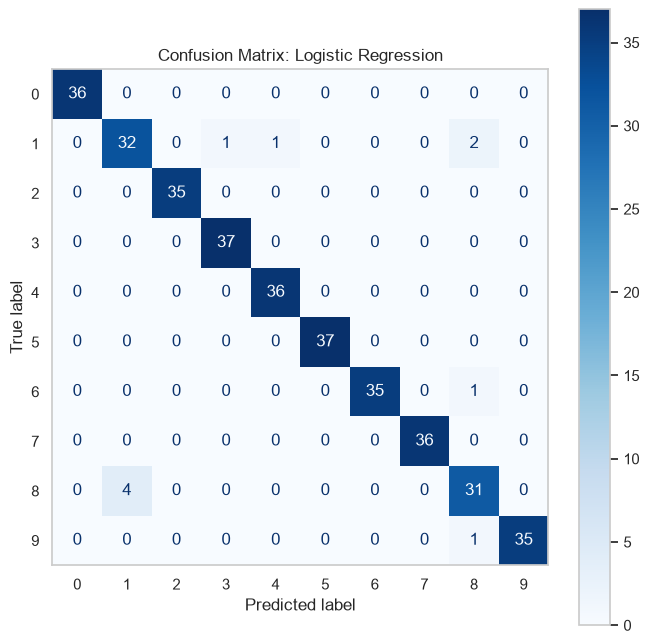

In [17]:
# ---- 5.1 Evaluation: Logistic Regression ----

# Get the best estimator (which is the pipeline with best parameters) from GridSearchCV
best_log_reg_model = grid_search_log_reg.best_estimator_

# Predict on X_test (Note: the pipeline handles scaling internally)
y_pred_lr = best_log_reg_model.predict(X_test)

# Print classification_report
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

# Display confusion matrix
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, ax=ax, cmap='Blues')
plt.title("Confusion Matrix: Logistic Regression")
plt.grid(False)
plt.show()

KNN Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.92      1.00      0.96        36
           2       0.95      1.00      0.97        35
           3       1.00      0.97      0.99        37
           4       0.97      0.94      0.96        36
           5       0.97      0.97      0.97        37
           6       0.97      1.00      0.99        36
           7       0.92      0.97      0.95        36
           8       0.97      0.89      0.93        35
           9       0.97      0.89      0.93        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360



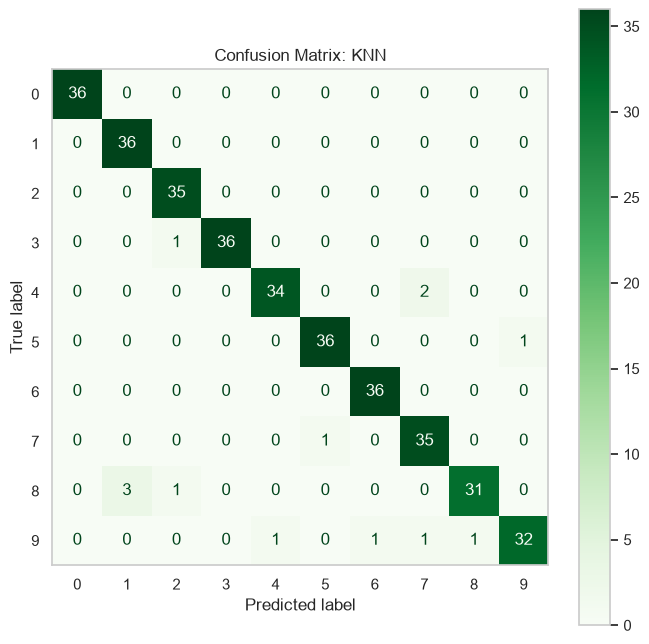

In [18]:
# ---- 5.2 Evaluation: KNN ----
# Predict on X_test_scaled
y_pred_knn = best_knn_model.predict(X_test)

# Print classification_report
print("KNN Classification Report:")
print(classification_report(y_test, y_pred_knn))

# Display confusion matrix
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_knn, ax=ax, cmap='Greens')
plt.title("Confusion Matrix: KNN")
plt.grid(False)
plt.show()

SVM Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      0.97      0.97        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.95      0.97      0.96        36
           5       1.00      1.00      1.00        37
           6       0.97      1.00      0.99        36
           7       0.95      1.00      0.97        36
           8       1.00      0.94      0.97        35
           9       1.00      0.94      0.97        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



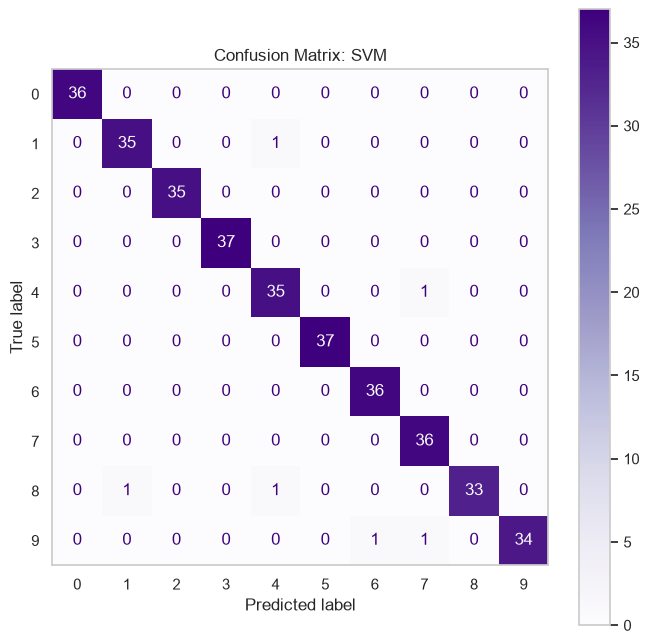

In [19]:
# ---- 5.3 Evaluation: SVM ----
# Predict on X_test_scaled
y_pred_svm = best_svm_model.predict(X_test)

# Print classification_report
print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))

# Display confusion matrix
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_svm, ax=ax, cmap='Purples')
plt.title("Confusion Matrix: SVM")
plt.grid(False)
plt.show()

Comparative table:
                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression  0.972222   0.972370  0.972222  0.972221
1                  KNN  0.963889   0.964752  0.963889  0.963611
2                  SVM  0.983333   0.983851  0.983333  0.983323


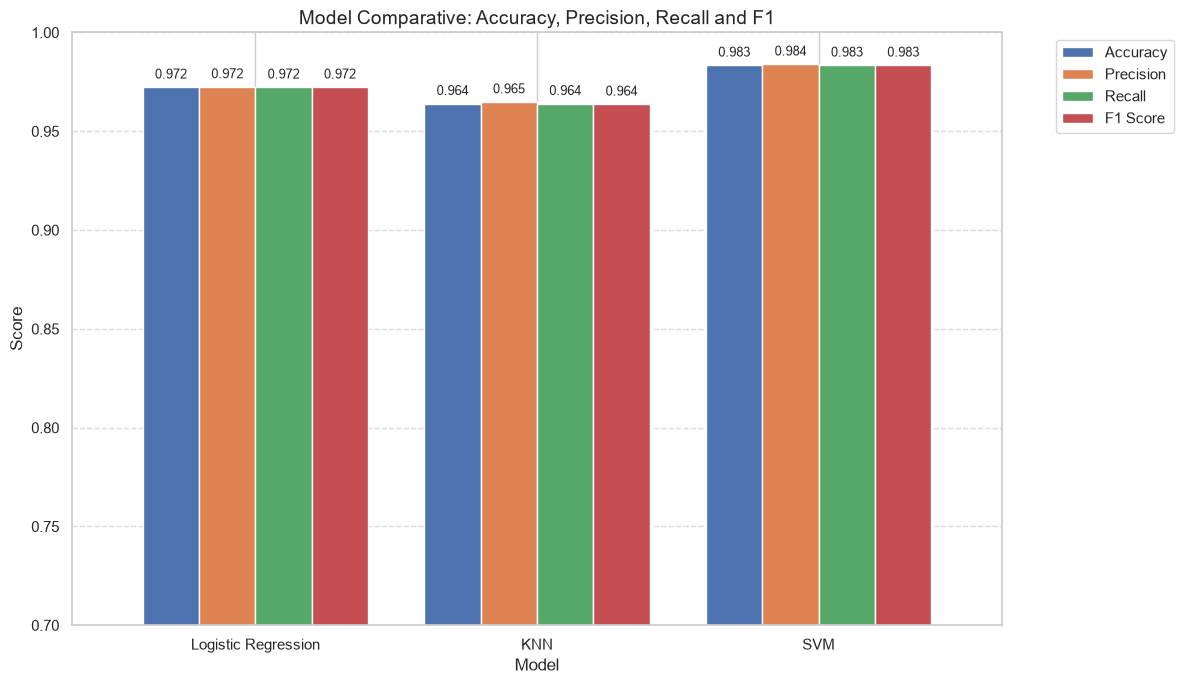

In [20]:
# ---- 5.4 Summary comparison table ----
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# DataFrame with columns: Model | Accuracy | F1 macro | F1 weighted

results_list = []
models = [
    ('Logistic Regression', y_pred_lr),
    ('KNN', y_pred_knn),
    ('SVM', y_pred_svm)
]

for name, preds in models:
    results_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds, average='weighted'),
        'Recall': recall_score(y_test, preds, average='weighted'),
        'F1 Score': f1_score(y_test, preds, average='weighted')
    })

df_results = pd.DataFrame(results_list)

print("Comparative table:")
print(df_results)

ax = df_results.set_index('Model').plot(kind='bar', figsize=(12, 7), width=0.8)

plt.title("Model Comparative: Accuracy, Precision, Recall and F1", fontsize=14)
plt.ylabel("Score", fontsize=12)
plt.xlabel("Model", fontsize=12)

plt.ylim(0.7, 1.0)

plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

for p in ax.patches:
    ax.annotate(f'{p.get_height():.3f}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=9)

plt.tight_layout()
plt.show()

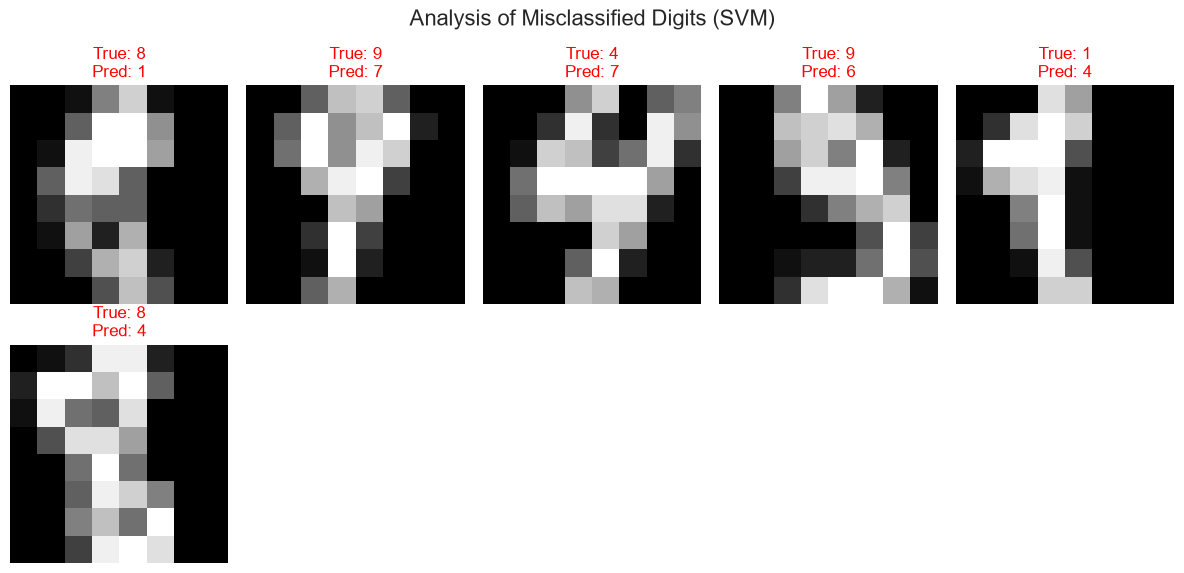

In [21]:
# ---- 5.5 Error analysis ----
# Display example images that the best model misclassified

# Identifying errors for SVM (the top performer)
errors_idx = np.where(y_pred_svm != y_test)[0]

plt.figure(figsize=(12, 6))
for i, idx in enumerate(errors_idx[:10]): # Show first 10 errors
    plt.subplot(2, 5, i + 1)
    # X_test[idx] contains the original 64 pixels
    plt.imshow(X_test[idx].reshape(8, 8), cmap='gray')
    plt.title(f"True: {y_test[idx]}\nPred: {y_pred_svm[idx]}", color='red')
    plt.axis('off')

plt.suptitle("Analysis of Misclassified Digits (SVM)", fontsize=16)
plt.tight_layout()
plt.show()

# Reflection: are the errors reasonable? Which digits are hardest to classify?
# Note: Often, digits like 1 and 8, or 7 and 9, are confused if written poorly.

---
## 6. Connection Between Unsupervised and Supervised Learning

### Thinking process
This is the most important part of the project. We want to answer:  
does the unsupervised analysis help us improve or better understand the predictions?

We explore three concrete connections:
1. **PCA as preprocessing:** does classifying in PCA space improve accuracy?
2. **Cluster labels as extra features:** does adding cluster membership help?
3. **Where does the model fail?** Do errors concentrate in overlapping regions of the t-SNE map?

Training SVM with 10 PCA components...
  Accuracy with 10 components: 0.9389
Training SVM with 20 PCA components...
  Accuracy with 20 components: 0.9667
Training SVM with 30 PCA components...
  Accuracy with 30 components: 0.9806
Training SVM with 40 PCA components...
  Accuracy with 40 components: 0.9833


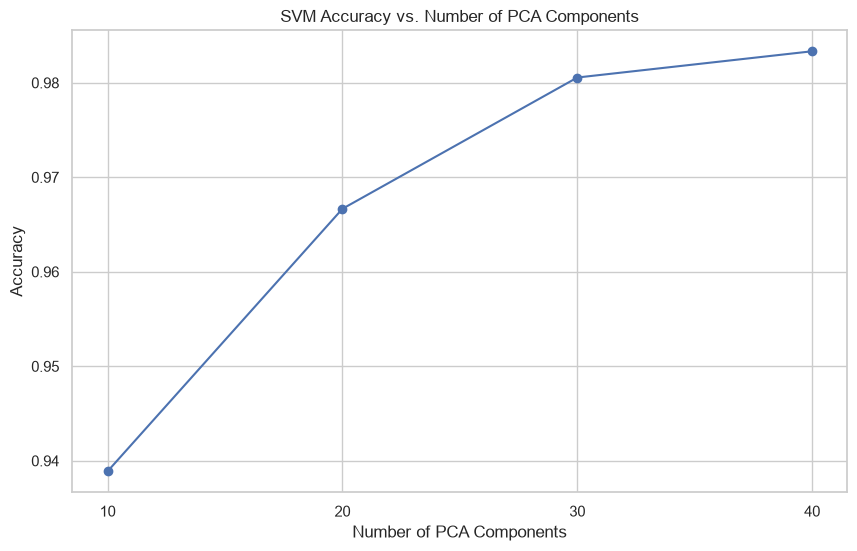

In [22]:
# ---- 6.1 Classification on PCA features ----
# Idea: reduce dimensionality with PCA, then classify.
# This may help by removing noisy, low-variance features.

# Define the number of PCA components to try
n_components_to_try = [10, 20, 30, 40]
accuracies = []

# Get the best SVM parameters from the previous GridSearchCV
best_svm_params = grid_search_svm.best_params_

for n_comp in n_components_to_try:
    print(f"Training SVM with {n_comp} PCA components...")
    # Create a pipeline that includes StandardScaler, PCA, and SVC
    # The StandardScaler is necessary here because PCA is sensitive to scale,
    # and the entire pipeline will be fitted on the original X_train.
    pipeline_pca_svm = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_comp, random_state=SEED)),
        ('svc', SVC(
            C=best_svm_params['svc__C'],
            gamma=best_svm_params['svc__gamma'],
            random_state=SEED
        ))
    ])

    # Fit the pipeline on the training data
    pipeline_pca_svm.fit(X_train, y_train)

    # Evaluate accuracy on the test data
    accuracy = pipeline_pca_svm.score(X_test, y_test)
    accuracies.append(accuracy)
    print(f"  Accuracy with {n_comp} components: {accuracy:.4f}")

# Plot accuracy vs number of PCA components
plt.figure(figsize=(10, 6))
plt.plot(n_components_to_try, accuracies, marker='o', linestyle='-')
plt.title('SVM Accuracy vs. Number of PCA Components')
plt.xlabel('Number of PCA Components')
plt.ylabel('Accuracy')
plt.xticks(n_components_to_try)
plt.grid(True)
plt.show()

# Reflection: what is the trade-off between compression and accuracy?
# Observe how increasing the number of components generally increases accuracy, up to a point.
# Fewer components mean more data compression but potentially lower accuracy due to loss of information.
# More components retain more information, leading to higher accuracy, but less compression.
# The optimal number of components is where accuracy plateaus or the gain in accuracy no longer justifies the increase in dimensionality.

In [23]:
# ---- 6.2 Cluster membership as an additional feature ----
# Idea: add the k-means cluster label as one extra feature.

# 1. Obtain cluster_label for each sample
# Use the K-Means model already fitted on X_scaled to predict labels for X_train_scaled and X_test_scaled
km_labels_train = kmeans.predict(X_train_scaled)
km_labels_test = kmeans.predict(X_test_scaled)

# Reshape labels to be a 2D array (column vector) for concatenation
km_labels_train_reshaped = km_labels_train.reshape(-1, 1)
km_labels_test_reshaped = km_labels_test.reshape(-1, 1)

# 2. Concatenate with X_scaled -> X_augmented
X_train_augmented = np.hstack((X_train_scaled, km_labels_train_reshaped))
X_test_augmented = np.hstack((X_test_scaled, km_labels_test_reshaped))

print(f"Shape of X_train_augmented: {X_train_augmented.shape}")
print(f"Shape of X_test_augmented: {X_test_augmented.shape}")

# 3. Train Logistic Regression with X_augmented
# We need to get the best parameters for Logistic Regression (C and solver)
# and create a new LogisticRegression model without the StandardScaler in the pipeline,
# as X_train_scaled and X_test_scaled are already scaled.
best_log_reg_C = grid_search_log_reg.best_params_['log_reg__C']
best_log_reg_solver = grid_search_log_reg.best_params_['log_reg__solver']

log_reg_augmented = LogisticRegression(
    C=best_log_reg_C,
    solver=best_log_reg_solver,
    max_iter=1000,
    random_state=SEED
)

log_reg_augmented.fit(X_train_augmented, y_train)
y_pred_lr_augmented = log_reg_augmented.predict(X_test_augmented)

# 4. Compare performance with the original Logistic Regression model
accuracy_lr_original = best_log_reg_model.score(X_test, y_test) # Using the existing best_log_reg_model pipeline
accuracy_lr_augmented = log_reg_augmented.score(X_test_augmented, y_test)

print(f"\nLogistic Regression Accuracy (original features): {accuracy_lr_original:.4f}")
print(f"Logistic Regression Accuracy (augmented with cluster labels): {accuracy_lr_augmented:.4f}")

Shape of X_train_augmented: (1437, 65)
Shape of X_test_augmented: (360, 65)



Logistic Regression Accuracy (original features): 0.9722
Logistic Regression Accuracy (augmented with cluster labels): 0.9694


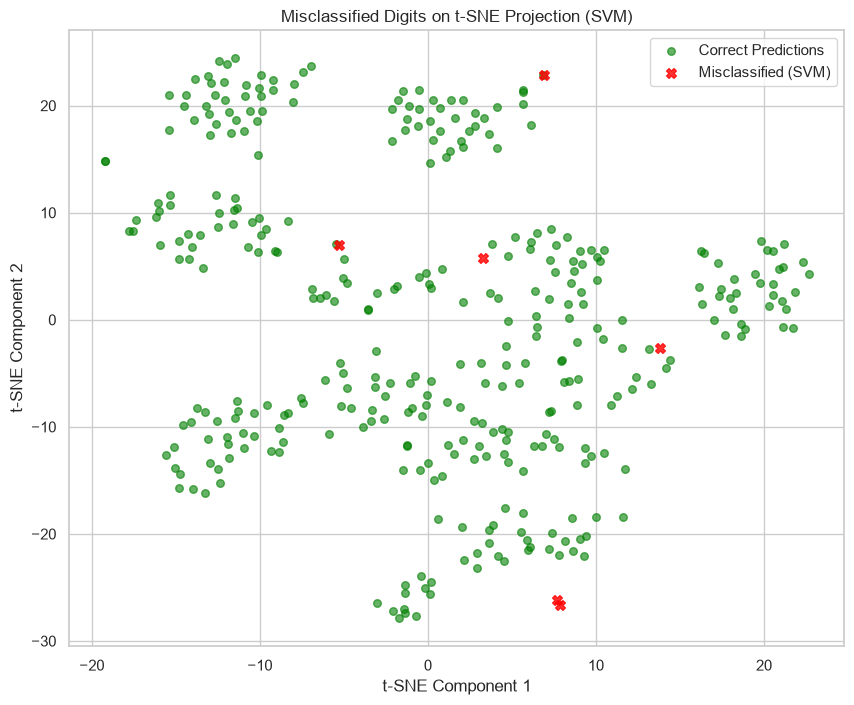

In [24]:
# ---- 6.3 Error map on t-SNE space ----
# Idea: project the test set onto the t-SNE embedding and highlight misclassifications.

# t-SNE cannot project new points, so we compute a separate embedding of the (scaled) test set
X_test_tsne = tsne_ref.fit_transform(X_test_scaled)

# Identify misclassified samples using the best SVM model's predictions
misclassified_mask = (y_pred_svm != y_test)
correctly_classified_mask = (y_pred_svm == y_test)

plt.figure(figsize=(10, 8))

# Plot correctly classified points (in green)
plt.scatter(
    X_test_tsne[correctly_classified_mask, 0],
    X_test_tsne[correctly_classified_mask, 1],
    c='green',
    label='Correct Predictions',
    alpha=0.6,
    s=30
)

# Plot misclassified points (in red)
plt.scatter(
    X_test_tsne[misclassified_mask, 0],
    X_test_tsne[misclassified_mask, 1],
    c='red',
    label='Misclassified (SVM)',
    alpha=0.8,
    s=50,
    marker='X'
)

plt.title('Misclassified Digits on t-SNE Projection (SVM)')
plt.xlabel('t-SNE Component 1')
plt.ylabel('t-SNE Component 2')
plt.legend()
plt.grid(True)
plt.show()